# 구구단 (Linear Regression)

### [셀 1] 환경 설정 및 PyTorch 설치
* 딥러닝 모델 구축 및 텐서(Tensor) 연산을 위한 PyTorch 라이브러리를 설치합니다.
* 이미 로컬 가상환경이나 Google Colab 환경에 설치되어 있다면 주석 상태를 유지합니다.

In [39]:
# ==============================================================================
# [셀 1] PyTorch 설치 (Colab 또는 로컬 Jupyter 환경용)
# - 딥러닝 모델 구축 및 텐서(Tensor) 연산을 위한 PyTorch 라이브러리를 설치합니다.
# - 이미 설치되어 있다면 주석 처리하거나 생략 가능합니다.
# ==============================================================================
# !pip install torch --quiet

### [셀 2] 라이브러리 임포트, 정규화 플래그(`USE_NORMALIZATION`) 및 구구단 데이터셋 정의
* **`USE_NORMALIZATION` (Boolean Flag):** 입출력 데이터에 정규화를 적용할지 여부를 선택하는 전역 스위치입니다.
  * `True` 설정 시: 입력($x$)을 최댓값 `9.0`으로, 타겟($y$)을 최댓값 `81.0`으로 나누어 $[0, 1]$ 범위로 스케일링합니다.
  * `False` 설정 시: 스케일 계수를 `1.0`으로 두어 원래의 정수 스케일($x \in [1, 9], y \in [2, 81]$)을 그대로 사용합니다.
* **`GuguDataset` 클래스:** `use_norm` 인자를 받아 내부 스케일 계수(`x_scale`, `y_scale`)를 동적으로 설정하므로, 추론 시에도 `normalize_x()`와 `denormalize_y()`를 코드 변경 없이 일관되게 호출하여 두 조건의 학습 결과를 정확히 비교할 수 있습니다.

In [40]:
# ==============================================================================
# [셀 2] 라이브러리 임포트, 정규화 플래그 설정 및 구구단 데이터셋 정의
# - USE_NORMALIZATION 플래그를 True 또는 False로 변경하여
#   정규화 적용 여부에 따른 학습 수렴 속도 및 예측 정확도를 비교할 수 있습니다.
# ==============================================================================
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# [실험 설정] 정규화 적용 여부 선택 (True: 정규화 적용 / False: 정규화 미적용)
# ------------------------------------------------------------------------------
USE_NORMALIZATION = True
norm_status_str = "정규화 적용" if USE_NORMALIZATION else "정규화 없음"
print(f"현재 실험 설정: [{norm_status_str}] (USE_NORMALIZATION = {USE_NORMALIZATION})")

# 구구단 데이터셋 (플래그에 따라 정규화 여부 자동 전환)
class GuguDataset(Dataset):
    def __init__(self, use_norm=True):
        self.data = []
        self.use_norm = use_norm

        # 플래그가 True이면 최댓값(9.0, 81.0)으로 스케일링, False이면 1.0(원본 유지)
        self.x_scale = 9.0 if self.use_norm else 1.0
        self.y_scale = 81.0 if self.use_norm else 1.0

        for a in range(2, 10):
            for b in range(1, 10):
                c = a * b
                x = torch.tensor([a, b], dtype=torch.float32) / self.x_scale
                y = torch.tensor([c], dtype=torch.float32) / self.y_scale
                self.data.append((x, y))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

    def normalize_x(self, x):
        return x / self.x_scale

    def denormalize_y(self, y):
        return y * self.y_scale

현재 실험 설정: [정규화 적용] (USE_NORMALIZATION = True)


### [셀 3] 다층 퍼셉트론(MLP) 회귀 모델 아키텍처 정의
* 두 입력 변수의 곱셈($f(a, b) = a \times b$)이라는 비선형 연속 함수를 근사(Function Approximation)하기 위해 다층 신경망(`GuguNet`)을 정의합니다.
* **네트워크 구조 (`nn.Sequential`):**
  * `Linear(2 -> 64)` $\rightarrow$ `ReLU` $\rightarrow$ `Linear(64 -> 128)` $\rightarrow$ `ReLU` $\rightarrow$ `Linear(128 -> 64)` $\rightarrow$ `ReLU` $\rightarrow$ `Linear(64 -> 1)`
* 연속적인 실수 값을 예측하는 **회귀(Regression)** 문제이므로 마지막 출력층에는 별도의 활성화 함수를 사용하지 않고 선형 출력을 그대로 반환합니다.

In [41]:
# ==============================================================================
# [셀 3] 모델 정의 (MLP: Multi-Layer Perceptron 회귀 모델)
# - 두 수의 곱셈(a * b)이라는 비선형 함수를 근사하기 위해 3개의 은닉층(64 -> 128 -> 64)과
#   ReLU 활성화 함수를 결합한 심층 신경망을 구성합니다.
# - 연속적인 수치를 예측하는 회귀(Regression) 모델이므로 출력층(Linear: 64 -> 1) 이후에는
#   별도의 활성화 함수를 적용하지 않습니다.
# ==============================================================================
class GuguNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)

### [셀 4] 학습 하이퍼파라미터 설정 및 학습 루프(Training Loop)
* 공정한 조건 비교를 위해 난수 시드(`torch.manual_seed(42)`)를 고정하고, `GuguDataset(use_norm=USE_NORMALIZATION)`으로 데이터셋을 생성합니다.
* **DataLoader:** 전체 72개 샘플을 미니배치 크기 16(`batch_size=16`)으로 나누어 로드하며, 매 에폭마다 데이터를 섞어줍니다(`shuffle=True`).
* **손실 함수 (`MSELoss`) 및 옵티마이저 (`Adam`, `lr=0.001`):** 총 1,000 Epoch 동안 학습을 수행하며 100 에폭마다 평균 손실을 출력합니다.
  * *참고:* 정규화 적용 시(`True`) 타겟이 $0 \sim 1$ 스케일이므로 Loss 수치 자체가 매우 작게 나타나고, 미적용 시(`False`) 타겟이 $2 \sim 81$ 스케일이므로 Loss 수치가 상대적으로 크게 출력됩니다.

In [42]:
# ==============================================================================
# [셀 4] 학습 설정 및 학습 루프(Training Loop)
# - 정규화 적용 여부에 따른 공정한 비교를 위해 랜덤 시드를 고정합니다.
# - USE_NORMALIZATION 플래그를 GuguDataset에 전달하여 데이터셋을 초기화합니다.
# ==============================================================================
from pathlib import Path
ROOT = Path("/content/TimesTable")
ROOT.mkdir(exist_ok=True)
best_loss = 1

torch.manual_seed(42)
np.random.seed(42)

dataset = GuguDataset(use_norm=USE_NORMALIZATION)
loader = DataLoader(dataset, batch_size=16, shuffle=True)
model = GuguNet()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10000
loss_history = []

print(f"=== [{norm_status_str}] 모델 학습 시작 ===")
for epoch in range(epochs):
    total_loss = 0.0
    for x_batch, y_batch in loader:
        optimizer.zero_grad()               # 기울기 초기화
        y_pred = model(x_batch)             # 순전파: 예측값 계산
        loss = criterion(y_pred, y_batch) * ((81.0**2) if USE_NORMALIZATION else 1.0) # MSE 손실 계산
        loss.backward()                     # 역전파: 기울기 계산
        optimizer.step()                    # 가중치 업데이트
        total_loss += loss.item() * x_batch.size(0)
    avg_loss = total_loss / len(dataset)

    if avg_loss <= best_loss:
        best_loss = avg_loss
        torch.save({"model": model.state_dict()}, ROOT / "best.pt")

    loss_history.append(avg_loss)
    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.9f}")

=== [정규화 적용] 모델 학습 시작 ===
Epoch 500/10000, Loss: 0.208798743
Epoch 1000/10000, Loss: 0.118588942
Epoch 1500/10000, Loss: 0.050049306
Epoch 2000/10000, Loss: 0.046317009
Epoch 2500/10000, Loss: 0.020473406
Epoch 3000/10000, Loss: 0.044470760
Epoch 3500/10000, Loss: 0.039318151
Epoch 4000/10000, Loss: 0.028931243
Epoch 4500/10000, Loss: 0.041851666
Epoch 5000/10000, Loss: 0.014527901
Epoch 5500/10000, Loss: 0.095101848
Epoch 6000/10000, Loss: 0.057354070
Epoch 6500/10000, Loss: 0.020196032
Epoch 7000/10000, Loss: 0.022251431
Epoch 7500/10000, Loss: 0.038356357
Epoch 8000/10000, Loss: 0.017730009
Epoch 8500/10000, Loss: 0.035065385
Epoch 9000/10000, Loss: 0.018699238
Epoch 9500/10000, Loss: 0.028809673
Epoch 10000/10000, Loss: 0.007303063


### [셀 5] 학습 손실(MSE Loss) 수렴 곡선 시각화
* 1,000 에폭 동안 기록된 `loss_history`를 꺾은선 그래프로 시각화합니다.
* 그래프 제목에 현재 설정된 `norm_status_str` (`정규화 적용` 또는 `정규화 없음`)이 자동으로 표시됩니다.

/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/211599500.py:12: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/i

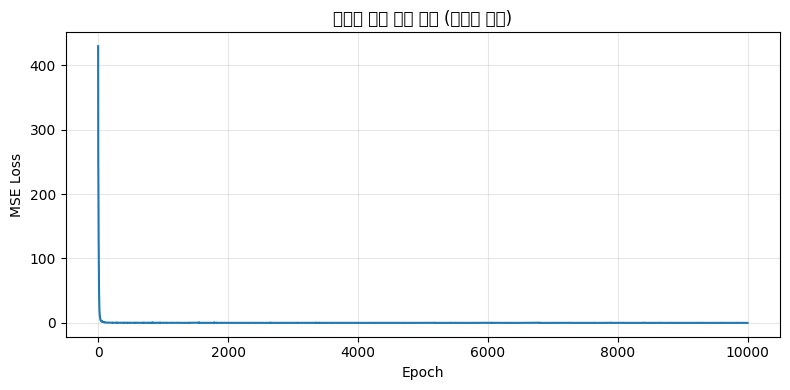

In [43]:
# ==============================================================================
# [셀 5] 학습 손실(MSE Loss) 시각화
# - 에폭 진행에 따른 평균 제곱 오차(MSE Loss)의 감소 추이를 그래프로 출력합니다.
# - 그래프 타이틀에 현재 플래그 상태(정규화 적용 / 정규화 없음)가 동적으로 반영됩니다.
# ==============================================================================
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title(f"구구단 학습 손실 곡선 ({norm_status_str})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### [셀 6] 모델 추론 및 전체 구구단 예측 오차 평가
* `dataset.normalize_x()`와 `dataset.denormalize_y()`는 `USE_NORMALIZATION` 상태에 따라 자동으로 스케일 변환(`True`일 때 $/9.0, \times 81.0$) 또는 원본 유지(`False`일 때 $/1.0, \times 1.0$)를 수행합니다.
* 최종 예측값은 모두 원래의 구구단 정수 스케일($2 \sim 81$)로 복원되어 평가되므로, 두 실험 방식 간의 **평균 절대 오차(MAE)**, **최대 오차**, **정확히 맞춘 개수(72개 중 정답 수)**를 동일한 기준에서 직접 비교할 수 있습니다.

In [44]:
# ==============================================================================
# [셀 6] 평가: 전체 구구단(72개 조합)에 대해 예측 오차 및 정확도 확인
# - normalize_x()와 denormalize_y()가 USE_NORMALIZATION 설정에 맞춰 자동으로 동작합니다.
# - 복원된 실수 예측값(y_pred_raw)을 반올림(round)하여 정수 정답(y_true)과 비교합니다.
# ==============================================================================
model.load_state_dict(torch.load(ROOT / "best.pt", map_location="cpu")["model"])
model.eval()
errors = []
raw_Errors = []

with torch.no_grad():
    for a in range(2, 10):
        for b in range(1, 10):
            x = torch.tensor([[a, b]], dtype=torch.float32)
            x_in = dataset.normalize_x(x)
            y_true = a * b

            # 모델 추론 및 원래 스케일로 복원
            y_pred_norm = model(x_in).item()
            y_pred_raw = dataset.denormalize_y(y_pred_norm)
            y_pred = round(y_pred_raw)

            err = abs(y_pred - y_true)
            raw_err = abs(y_pred_raw - y_true)
            errors.append((a, b, y_true, y_pred, err))
            raw_Errors.append(raw_err)

# 오차 통계 출력
err_vals = [e[4] for e in errors]
print(f"=== [{norm_status_str}] 최종 평가 결과 ===")
print(f"반올림 전 연속값 기준 MAE: {np.mean(raw_Errors):.4f}")
print(f"반올림 후 정수 기준 평균 절대 오차(MAE): {np.mean(err_vals):.3f}")
print(f"최대 오차: {np.max(err_vals)}")
print(f"정확히 맞춘 개수: {sum(1 for e in err_vals if e == 0)}/{len(err_vals)} ({100 * sum(1 for e in err_vals if e == 0) / len(err_vals):.1f}%)")

# 전체 결과 테이블 출력
print("\n전체 예측 결과 (a, b, 실제, 예측, 오차):")
for e in errors:
    print(e)

=== [정규화 적용] 최종 평가 결과 ===
반올림 전 연속값 기준 MAE: 0.0549
반올림 후 정수 기준 평균 절대 오차(MAE): 0.000
최대 오차: 0
정확히 맞춘 개수: 72/72 (100.0%)

전체 예측 결과 (a, b, 실제, 예측, 오차):
(2, 1, 2, 2, 0)
(2, 2, 4, 4, 0)
(2, 3, 6, 6, 0)
(2, 4, 8, 8, 0)
(2, 5, 10, 10, 0)
(2, 6, 12, 12, 0)
(2, 7, 14, 14, 0)
(2, 8, 16, 16, 0)
(2, 9, 18, 18, 0)
(3, 1, 3, 3, 0)
(3, 2, 6, 6, 0)
(3, 3, 9, 9, 0)
(3, 4, 12, 12, 0)
(3, 5, 15, 15, 0)
(3, 6, 18, 18, 0)
(3, 7, 21, 21, 0)
(3, 8, 24, 24, 0)
(3, 9, 27, 27, 0)
(4, 1, 4, 4, 0)
(4, 2, 8, 8, 0)
(4, 3, 12, 12, 0)
(4, 4, 16, 16, 0)
(4, 5, 20, 20, 0)
(4, 6, 24, 24, 0)
(4, 7, 28, 28, 0)
(4, 8, 32, 32, 0)
(4, 9, 36, 36, 0)
(5, 1, 5, 5, 0)
(5, 2, 10, 10, 0)
(5, 3, 15, 15, 0)
(5, 4, 20, 20, 0)
(5, 5, 25, 25, 0)
(5, 6, 30, 30, 0)
(5, 7, 35, 35, 0)
(5, 8, 40, 40, 0)
(5, 9, 45, 45, 0)
(6, 1, 6, 6, 0)
(6, 2, 12, 12, 0)
(6, 3, 18, 18, 0)
(6, 4, 24, 24, 0)
(6, 5, 30, 30, 0)
(6, 6, 36, 36, 0)
(6, 7, 42, 42, 0)
(6, 8, 48, 48, 0)
(6, 9, 54, 54, 0)
(7, 1, 7, 7, 0)
(7, 2, 14, 14, 0)
(7, 3, 21, 21, 0)
(7, 4, 28, 

### [셀 7] 구구단 예측 오차 히트맵(Heatmap) 시각화
* $8 \times 9$ 오차 행렬(`error_matrix`)을 히트맵으로 시각화하며, 그래프 제목에 현재 정규화 적용 여부가 자동으로 반영됩니다.

/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_538/1271943215.py:18: UserWarning: Glyph 55176 (\N{HANGUL SYLLABLE HI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp

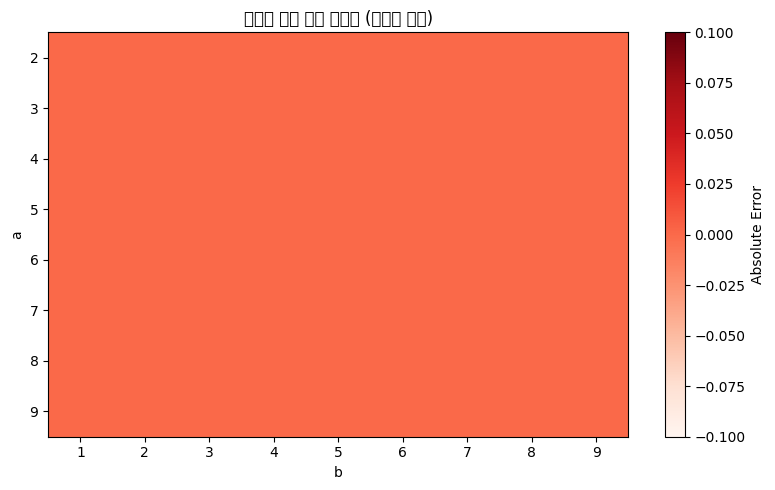

In [45]:
# ==============================================================================
# [셀 7] 오차 히트맵(Heatmap) 시각화
# - 2~9단(행, 8개) x 1~9(열, 9개) 크기의 2차원 배열에 각 조합의 절대 오차를 매핑합니다.
# - 히트맵(imshow)을 통해 특정 구구단 영역에서 오차가 집중되는지 시각적으로 분석합니다.
# ==============================================================================
error_matrix = np.zeros((8, 9))  # a:2~9 (8개), b:1~9 (9개)
for a, b, _, _, err in errors:
    error_matrix[a-2, b-1] = err

plt.figure(figsize=(8, 5))
plt.imshow(error_matrix, cmap='Reds', aspect='auto')
plt.colorbar(label='Absolute Error')
plt.xticks(range(9), range(1, 10))
plt.yticks(range(8), range(2, 10))
plt.xlabel('b')
plt.ylabel('a')
plt.title(f'구구단 예측 오차 히트맵 ({norm_status_str})')
plt.tight_layout()
plt.show()

### [셀 8] (선택) 정규화 적용(`True`) vs 미적용(`False`) 동시 학습 및 한눈에 비교하기
* 플래그를 일일이 바꾸며 두 번 실행하지 않고도, 한 번의 셀 실행으로 **`USE_NORMALIZATION = True`**와 **`USE_NORMALIZATION = False`** 두 가지 경우를 동일한 초기 가중치에서 각각 학습시켜 **원래 스케일 기준의 수렴 곡선과 오차 히트맵, 최종 정확도를 나란히 비교**할 수 있는 통합 비교 셀입니다.

두 조건(정규화 O vs 정규화 X) 비교 학습 진행 중...

[비교 요약]
1) 정규화 적용 (True)  -> 정확도: 72/72 (100.0%), 정수 기준 MAE: 0.000, 최종 원본스케일 MSE: 0.0054
2) 정규화 없음 (False) -> 정확도: 70/72 (97.2%), 정수 기준 MAE: 0.028, 최종 원본스케일 MSE: 0.0291


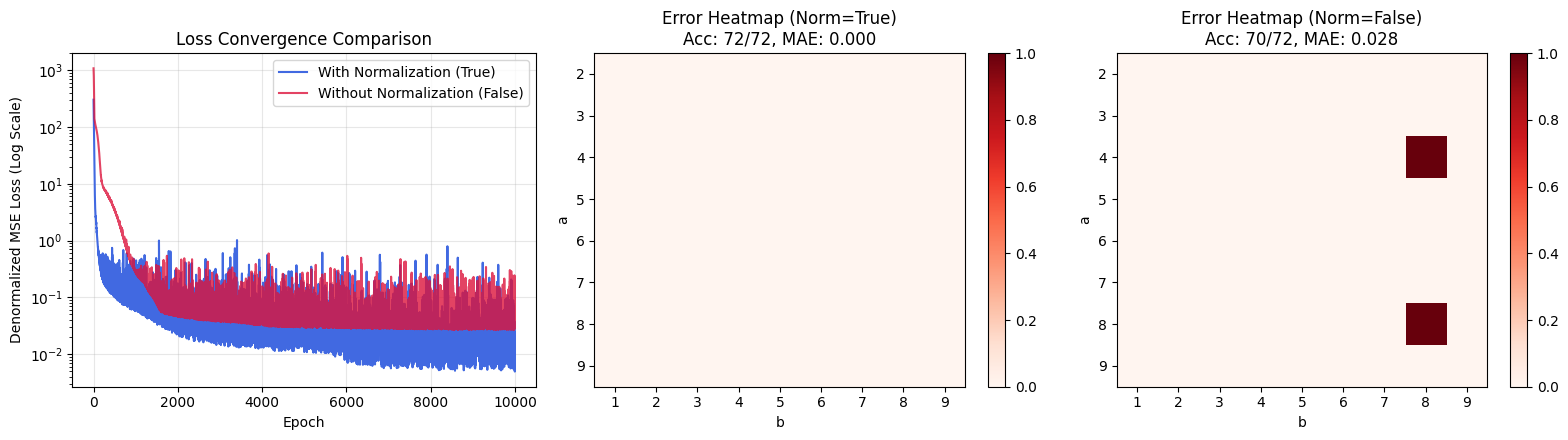

In [46]:
# ==============================================================================
# [셀 8] 정규화 적용(True) vs 정규화 미적용(False) 직접 비교 실험
# - 동일한 초기 가중치와 하이퍼파라미터에서 정규화 유무만 다르게 하여 두 모델을 학습합니다.
# - 공정한 손실 비교를 위해 두 모델 모두 '원래 구구단 스케일(2~81)'로 환산한 MSE와
#   오차 히트맵을 나란히 시각화하여 비교합니다.
# ==============================================================================
def run_experiment(use_norm, epochs=1000, lr=0.001):
    torch.manual_seed(42)
    np.random.seed(42)

    ds = GuguDataset(use_norm=use_norm)
    ldr = DataLoader(ds, batch_size=16, shuffle=True)
    net = GuguNet()
    crit = nn.MSELoss()
    opt = optim.Adam(net.parameters(), lr=lr)

    raw_mse_history = []
    for _ in range(epochs):
        for xb, yb in ldr:
            opt.zero_grad()
            pred = net(xb)
            loss = crit(pred, yb) * ((81.0**2) if use_norm else 1.0)
            loss.backward()
            opt.step()

        # 매 에폭마다 원래 스케일(2~81) 기준으로 MSE 측정 (직접 비교용)
        net.eval()
        with torch.no_grad():
            sq_errs = []
            for x_item, y_item in ds:
                p_raw = ds.denormalize_y(net(x_item.unsqueeze(0)).item())
                t_raw = ds.denormalize_y(y_item.item())
                sq_errs.append((p_raw - t_raw) ** 2)
            raw_mse_history.append(np.mean(sq_errs))
        net.train()

    # 최종 오차 행렬 및 정확도 산출
    net.eval()
    err_mat = np.zeros((8, 9))
    err_list = []
    with torch.no_grad():
        for a in range(2, 10):
            for b in range(1, 10):
                x_t = ds.normalize_x(torch.tensor([[a, b]], dtype=torch.float32))
                p_val = round(ds.denormalize_y(net(x_t).item()))
                e_val = abs(p_val - (a * b))
                err_mat[a-2, b-1] = e_val
                err_list.append(e_val)

    acc = sum(1 for e in err_list if e == 0)
    mae = np.mean(err_list)
    return raw_mse_history, err_mat, acc, mae

print("두 조건(정규화 O vs 정규화 X) 비교 학습 진행 중...")
hist_norm, mat_norm, acc_norm, mae_norm = run_experiment(use_norm=True, epochs=epochs)
hist_raw, mat_raw, acc_raw, mae_raw = run_experiment(use_norm=False, epochs=epochs)

print(f"\n[비교 요약]")
print(f"1) 정규화 적용 (True)  -> 정확도: {acc_norm}/72 ({100*acc_norm/72:.1f}%), 정수 기준 MAE: {mae_norm:.3f}, 최종 원본스케일 MSE: {hist_norm[-1]:.4f}")
print(f"2) 정규화 없음 (False) -> 정확도: {acc_raw}/72 ({100*acc_raw/72:.1f}%), 정수 기준 MAE: {mae_raw:.3f}, 최종 원본스케일 MSE: {hist_raw[-1]:.4f}")

# 시각화 비교 (수렴 곡선 & 히트맵)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. 원본 스케일 환산 MSE 손실 비교 곡선 (Log Scale)
axes[0].plot(hist_norm, label='With Normalization (True)', color='royalblue')
axes[0].plot(hist_raw, label='Without Normalization (False)', color='crimson', alpha=0.8)
axes[0].set_yscale('log')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Denormalized MSE Loss (Log Scale)')
axes[0].set_title('Loss Convergence Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. 정규화 적용 오차 히트맵
vmax = max(np.max(mat_norm), np.max(mat_raw), 1)
im1 = axes[1].imshow(mat_norm, cmap='Reds', aspect='auto', vmin=0, vmax=vmax)
axes[1].set_title(f'Error Heatmap (Norm=True)\nAcc: {acc_norm}/72, MAE: {mae_norm:.3f}')
axes[1].set_xticks(range(9), range(1, 10))
axes[1].set_yticks(range(8), range(2, 10))
axes[1].set_xlabel('b')
axes[1].set_ylabel('a')
fig.colorbar(im1, ax=axes[1])

# 3. 정규화 미적용 오차 히트맵
im2 = axes[2].imshow(mat_raw, cmap='Reds', aspect='auto', vmin=0, vmax=vmax)
axes[2].set_title(f'Error Heatmap (Norm=False)\nAcc: {acc_raw}/72, MAE: {mae_raw:.3f}')
axes[2].set_xticks(range(9), range(1, 10))
axes[2].set_yticks(range(8), range(2, 10))
axes[2].set_xlabel('b')
axes[2].set_ylabel('a')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()